<a href="https://colab.research.google.com/github/aditiprasannna/DLG-lab/blob/main/dlglab4pt2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import os
import subprocess


import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input, decode_predictions
import numpy as np
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

print("All libraries imported successfully!")
print("OpenCV version:", cv2.__version__)
print("Selective Search available:", hasattr(cv2, "ximgproc") and hasattr(cv2.ximgproc, "segmentation"))



All libraries imported successfully!
OpenCV version: 5.0.0
Selective Search available: True


In [2]:

model = VGG16(weights="imagenet", include_top=True)

print("VGG16 model loaded successfully!")


553467096/553467096 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
VGG16 model loaded successfully!


In [3]:

def get_region_proposals(img, max_regions=200):
    try:
        ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
        ss.setBaseImage(img)
        ss.switchToSelectiveSearchFast()

        boxes = [
            (x, y, w, h)
            for (x, y, w, h) in ss.process()
            if w > 40 and h > 40
        ]

        if boxes:
            return boxes[:max_regions]

    except Exception:
        pass

    H, W = img.shape[:2]
    boxes = []

    for s in (0.6, 0.4, 0.25):
        bw, bh = int(W * s), int(H * s)

        for y in range(0, H - bh + 1, max(1, bh // 2)):
            for x in range(0, W - bw + 1, max(1, bw // 2)):
                boxes.append((x, y, bw, bh))

    return boxes[:max_regions]

print("Selective Search function defined successfully!")


Selective Search function defined successfully!


In [4]:

def non_max_suppression(dets, iou_thr=0.3):
    if not dets:
        return []

    boxes = np.array(
        [[x, y, x + w, y + h] for (x, y, w, h), _, _ in dets],
        dtype=float
    )

    scores = np.array([s for _, _, s in dets])
    order = scores.argsort()[::-1]
    keep = []

    while len(order):
        i = order[0]
        keep.append(i)
        rest = order[1:]

        xx1 = np.maximum(boxes[i, 0], boxes[rest, 0])
        yy1 = np.maximum(boxes[i, 1], boxes[rest, 1])
        xx2 = np.minimum(boxes[i, 2], boxes[rest, 2])
        yy2 = np.minimum(boxes[i, 3], boxes[rest, 3])

        w = np.clip(xx2 - xx1, 0, None)
        h = np.clip(yy2 - yy1, 0, None)
        inter = w * h

        area_i = (boxes[i, 2] - boxes[i, 0]) * (boxes[i, 3] - boxes[i, 1])
        area_r = (boxes[rest, 2] - boxes[rest, 0]) * (boxes[rest, 3] - boxes[rest, 1])

        order = rest[inter / (area_i + area_r - inter + 1e-9) < iou_thr]

    return [dets[i] for i in keep]

print("Non-Maximum Suppression function defined successfully!")


Non-Maximum Suppression function defined successfully!


In [5]:

uploaded = files.upload()

image_path = next(iter(uploaded))
img = cv2.imread(image_path)

if img is None:
    raise ValueError("Unable to read the uploaded image.")

H0, W0 = img.shape[:2]
img = cv2.resize(img, (600, int(H0 * 600.0 / W0)))

boxes = get_region_proposals(img, max_regions=200)

print("Image uploaded successfully!")
print("Image dimensions:", img.shape)
print("Region proposals:", len(boxes))


Saving Screenshot 2026-10-28 120011.png to Screenshot 2026-10-28 120011 (1).png
Image uploaded successfully!
Image dimensions: (580, 600, 3)
Region proposals: 200


In [7]:

boxes = boxes[:50]

crops = np.array([
    cv2.resize(img[y:y+h, x:x+w], (224, 224))
    for (x, y, w, h) in boxes
], dtype=np.float32)

preds = model.predict(
    preprocess_input(crops),
    batch_size=16,
    verbose=1
)

print("Region classification completed!")
print("Number of regions classified:", len(preds))


4/4 ━━━━━━━━━━━━━━━━━━━━ 28s 7s/step
Region classification completed!
Number of regions classified: 50


In [8]:

detections = []

for (x, y, w, h), p in zip(boxes, preds):
    _, label, prob = decode_predictions(p[None], top=1)[0][0]

    if prob > 0.90:
        detections.append(((x, y, w, h), label, float(prob)))

print("High-confidence detections:", len(detections))

detections = non_max_suppression(detections, iou_thr=0.3)

print("Detections after removing duplicates:", len(detections))


35363/35363 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
High-confidence detections: 0
Detections after removing duplicates: 0


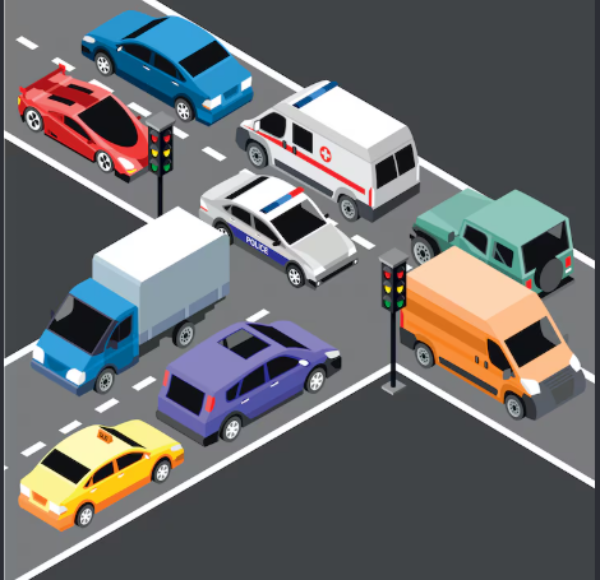

In [9]:

for (x, y, w, h), label, score in detections:
    cv2.rectangle(img, (x, y), (x + w, y + h), (0, 255, 0), 2)

    cv2.putText(
        img,
        f"{label}: {score:.2f}",
        (x, max(18, y - 6)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0, 255, 0),
        2
    )

cv2_imshow(img)


In [10]:

output_path = "/content/program2_object_detection.jpg"

cv2.imwrite(output_path, img)
files.download(output_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>